In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

In [2]:
data = pd.read_csv("one - one.csv")
print(data.shape)
print(data.head())
print(data.describe())

(36000, 3)
   Time  AI0 (Class 1)  AI0 (Class2)
0     1       0.005048      0.004848
1     2       0.005018      0.004862
2     3       0.005029      0.004851
3     4       0.005060      0.004826
4     5       0.005093      0.004818
               Time  AI0 (Class 1)  AI0 (Class2)
count  36000.000000   36000.000000  36000.000000
mean   18000.500000       0.004826      0.004939
std    10392.449182       0.000092      0.000277
min        1.000000       0.004198      0.002809
25%     9000.750000       0.004789      0.004876
50%    18000.500000       0.004818      0.004954
75%    27000.250000       0.004867      0.005015
max    36000.000000       0.005411      0.006902


In [3]:
time_ms = data["Time"].values / 2
class1 = data["AI0 (Class 1)"].values
class2 = data["AI0 (Class2)"].values
print(f"Samples in Class 1: {len(class1)}")
print(f"Samples in Class 2: {len(class2)}")

Samples in Class 1: 36000
Samples in Class 2: 36000


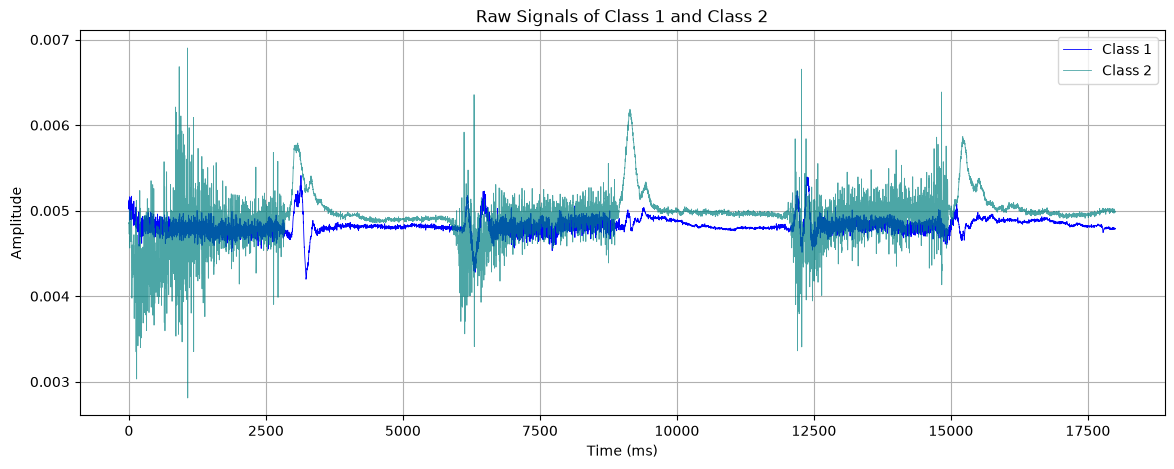

In [4]:
plt.figure(figsize=(14,5))
plt.plot(time_ms, class1, label="Class 1", color="blue", linewidth=0.6)
plt.plot(time_ms, class2, label="Class 2", color="teal", linewidth=0.6, alpha=0.7)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("Raw Signals of Class 1 and Class 2")
plt.legend()
plt.grid(True)
plt.show()

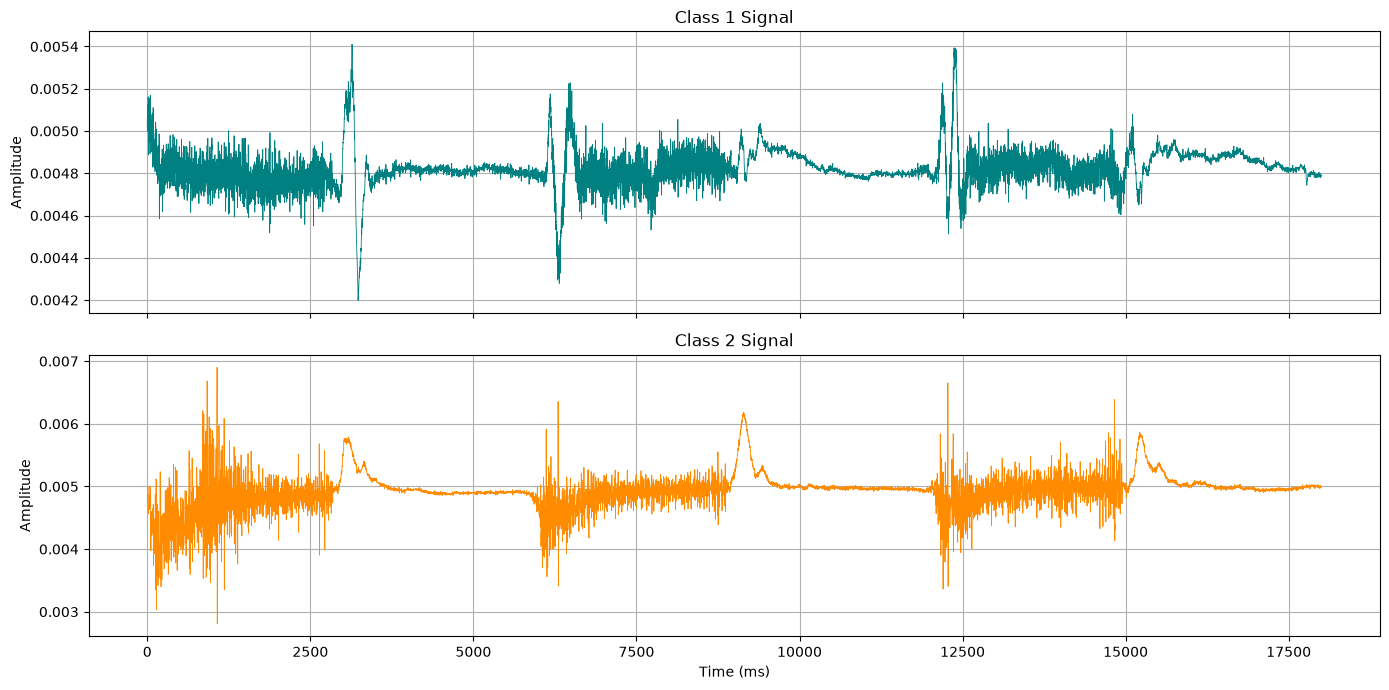

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(14,7), sharex=True)
ax[0].plot(time_ms, class1, color="teal", linewidth=0.6)  
ax[0].set_title("Class 1 Signal")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True)
ax[1].plot(time_ms, class2, color="darkorange", linewidth=0.6)  
ax[1].set_title("Class 2 Signal")
ax[1].set_xlabel("Time (ms)")
ax[1].set_ylabel("Amplitude")
ax[1].grid(True)
plt.tight_layout()
plt.show()

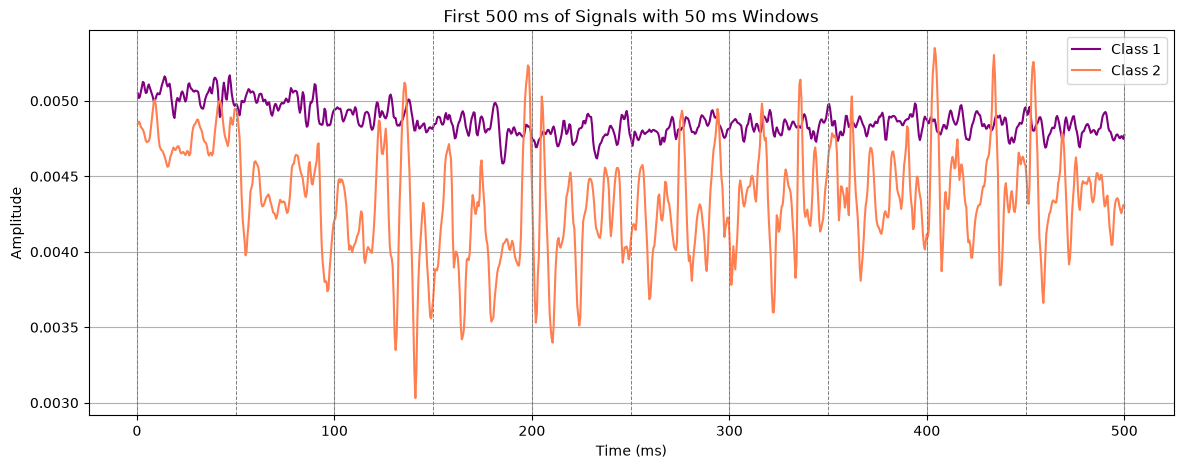

In [6]:
plt.figure(figsize=(14,5))
plt.plot(time_ms[:1000], class1[:1000], label="Class 1", color="purple")  
plt.plot(time_ms[:1000], class2[:1000], label="Class 2", color="coral")   
for i in range(0, 501, 50):
    plt.axvline(i, color="gray", linestyle="--", linewidth=0.7)
plt.xlabel("Time (ms)")
plt.ylabel("Amplitude")
plt.title("First 500 ms of Signals with 50 ms Windows")
plt.legend()
plt.grid(True)
plt.show()

In [7]:
fs = 2
window_ms = 50
window_size = fs * window_ms
print(f"Window size: {window_size} samples")
print(f"Number of windows per class: {len(class1)//window_size}")

Window size: 100 samples
Number of windows per class: 360


In [8]:
def findMean(x):
    total = 0
    for i in range(len(x)):
        total = total + x[i]
    return total / len(x)

def findVariance(x):
    m = findMean(x)
    total = 0
    for i in range(len(x)):
        total = total + (x[i] - m) ** 2
    return total / len(x)

def findStd(x):
    return findVariance(x) ** 0.5

def findMAV(x):
    total = 0
    for i in range(len(x)):
        total = total + abs(x[i])
    return total / len(x)

def findZeroCrossing(x):
    m = findMean(x)
    count = 0
    for i in range(1, len(x)):
        if (x[i-1] - m) * (x[i] - m) < 0:
            count = count + 1
    return count

In [9]:
def extractFeatures(signal, window_size, label):
    features = []
    n = len(signal) // window_size
    for w in range(n):
        x = signal[w*window_size:(w+1)*window_size]
        features.append([findMean(x), findVariance(x), findStd(x), findMAV(x), findZeroCrossing(x), label])
    return features

In [10]:
f1 = extractFeatures(class1, window_size, 0)
f2 = extractFeatures(class2, window_size, 1)
df = pd.DataFrame(f1 + f2, columns=["Mean", "Variance", "Std", "MAV", "ZeroCrossing", "Label"])
print(df.shape)
print(df.head())
print(df.tail())
print(df["Label"].value_counts())

(720, 6)
       Mean      Variance       Std       MAV  ZeroCrossing  Label
0  0.005049  3.760553e-09  0.000061  0.005049            16      0
1  0.004976  5.026821e-09  0.000071  0.004976            13      0
2  0.004894  3.540336e-09  0.000060  0.004894            13      0
3  0.004829  5.796981e-09  0.000076  0.004829            11      0
4  0.004787  4.623876e-09  0.000068  0.004787            16      0
         Mean      Variance       Std       MAV  ZeroCrossing  Label
715  0.005001  1.275940e-10  0.000011  0.005001            11      1
716  0.005002  1.306894e-10  0.000011  0.005002            15      1
717  0.005009  1.319018e-10  0.000011  0.005009            19      1
718  0.005005  8.586416e-11  0.000009  0.005005             8      1
719  0.004995  1.521513e-10  0.000012  0.004995            10      1
Label
0    360
1    360
Name: count, dtype: int64


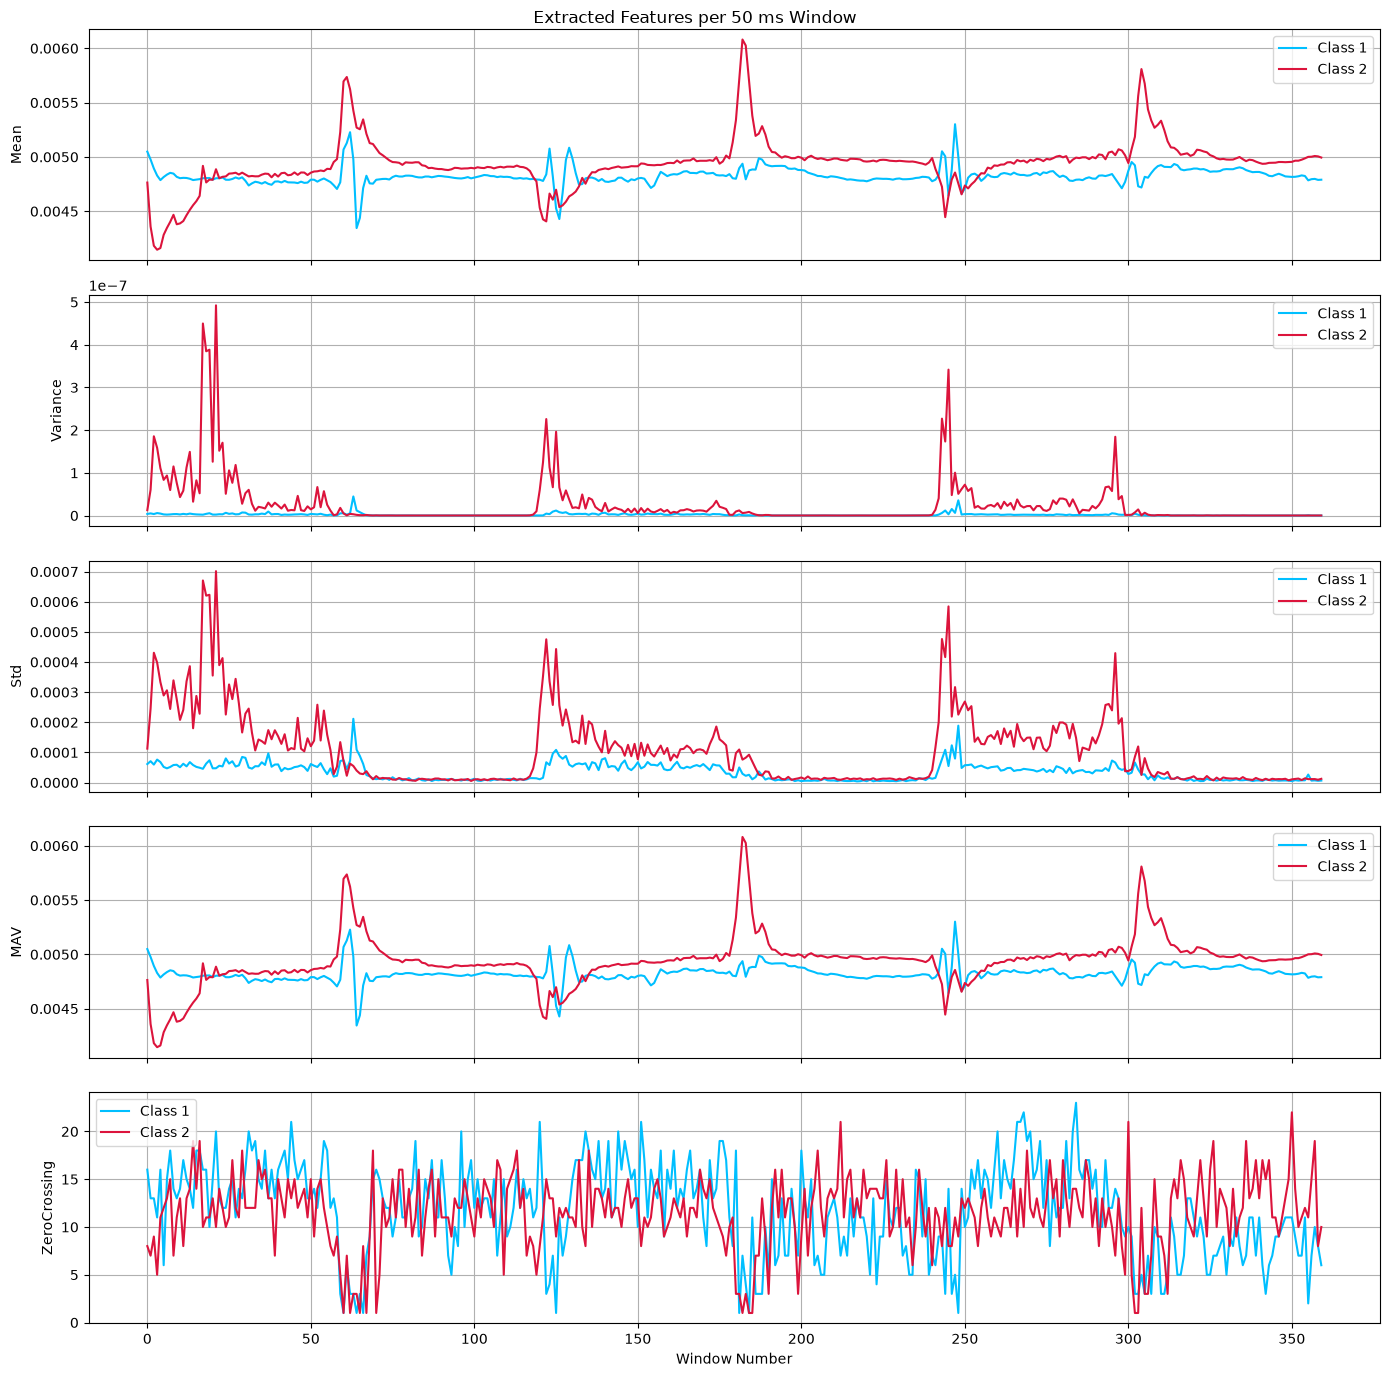

In [11]:
feature_names = ["Mean", "Variance", "Std", "MAV", "ZeroCrossing"]
fig, ax = plt.subplots(5, 1, figsize=(14,14), sharex=True)
for i in range(5):
    ax[i].plot(df[df["Label"]==0][feature_names[i]].values, label="Class 1", color="deepskyblue") 
    ax[i].plot(df[df["Label"]==1][feature_names[i]].values, label="Class 2", color="crimson")     
    ax[i].set_ylabel(feature_names[i])
    ax[i].legend()
    ax[i].grid(True)
ax[4].set_xlabel("Window Number")
plt.suptitle("Extracted Features per 50 ms Window")
plt.tight_layout()
plt.show()

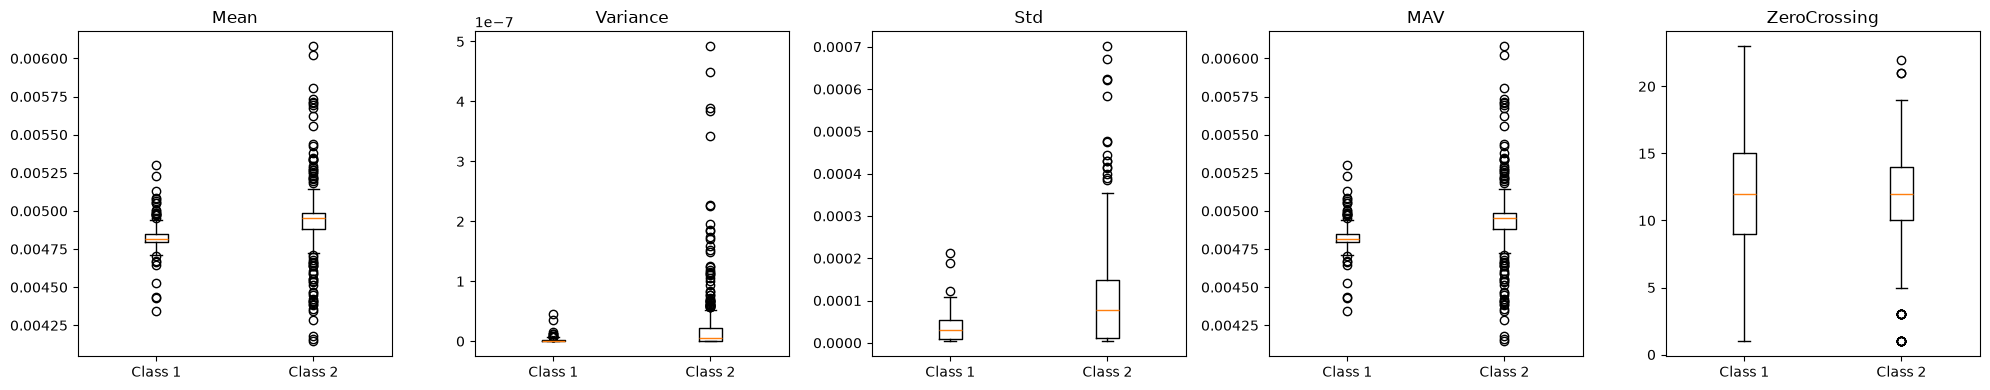

In [12]:
fig, ax = plt.subplots(1, 5, figsize=(20,4))
for i in range(5):
    ax[i].boxplot([df[df["Label"]==0][feature_names[i]], df[df["Label"]==1][feature_names[i]]])
    ax[i].set_xticks([1, 2])
    ax[i].set_xticklabels(["Class 1", "Class 2"])
    ax[i].set_title(feature_names[i])
plt.tight_layout()
plt.show()

In [13]:
X = df[feature_names].values
y = df["Label"].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print(X_scaled.shape)

(720, 5)


In [14]:
pca_full = PCA()
pca_full.fit(X_scaled)
print(f"Explained variance ratio: {pca_full.explained_variance_ratio_}")
print(f"Cumulative variance: {np.cumsum(pca_full.explained_variance_ratio_)}")

Explained variance ratio: [0.4957951  0.31456278 0.16871825 0.02092387 0.        ]
Cumulative variance: [0.4957951  0.81035788 0.97907613 1.         1.        ]


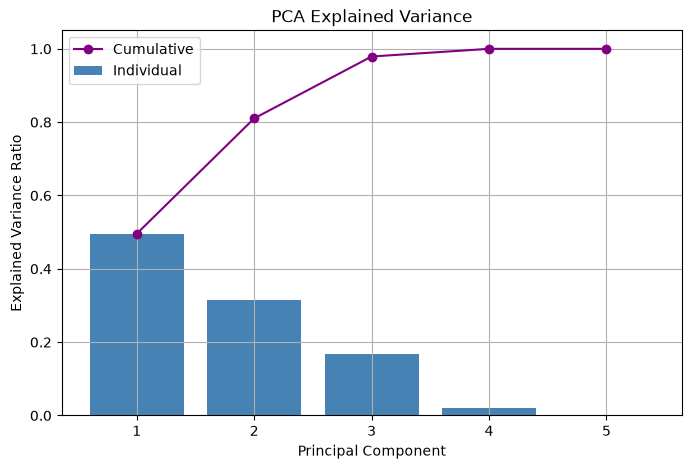

In [15]:
plt.figure(figsize=(8,5))
plt.bar(range(1,6), pca_full.explained_variance_ratio_, label="Individual", color="steelblue") 
plt.plot(range(1,6), np.cumsum(pca_full.explained_variance_ratio_), marker="o", color="purple", label="Cumulative")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA Explained Variance")
plt.legend()
plt.grid(True)
plt.show()

In [16]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)
print(X_pca.shape)
print(f"Variance kept with 3 components: {sum(pca.explained_variance_ratio_)}")

(720, 3)
Variance kept with 3 components: 0.9790761303594033


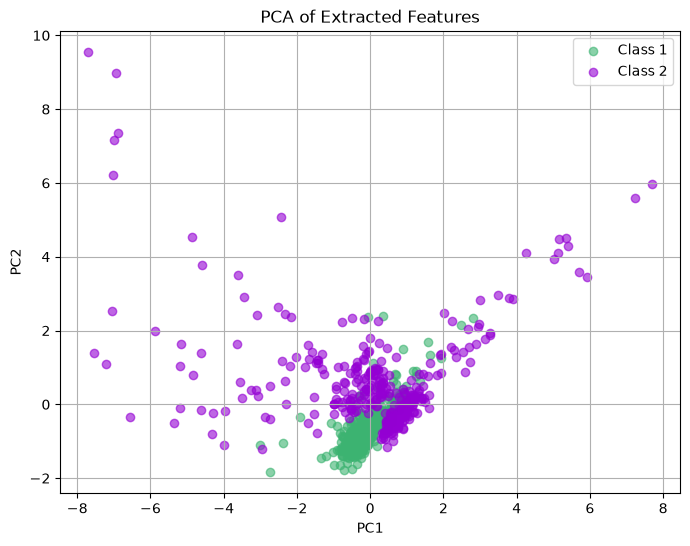

In [17]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[y==0,0], X_pca[y==0,1], label="Class 1", color="mediumseagreen", alpha=0.6) 
plt.scatter(X_pca[y==1,0], X_pca[y==1,1], label="Class 2", color="darkviolet", alpha=0.6)     
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of Extracted Features")
plt.legend()
plt.grid(True)
plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train size: {X_train.shape}")
print(f"Test size: {X_test.shape}")

Train size: (576, 3)
Test size: (144, 3)


In [19]:
models = {
    "LR": LogisticRegression(),
    "SVM": SVC(kernel="rbf"),
    "NB": GaussianNB(),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "DT": DecisionTreeClassifier(random_state=42),
    "RF": RandomForestClassifier(n_estimators=100, random_state=42)
}

In [20]:
results = []
predictions = {}
for name in models:
    model = models[name]
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    acc = accuracy_score(y_test, y_pred)
    pre = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1s = f1_score(y_test, y_pred)
    results.append([name, acc, pre, rec, f1s])
    print(f"{name} -> Accuracy: {acc:.4f}, Precision: {pre:.4f}, Recall: {rec:.4f}, F1: {f1s:.4f}")

LR -> Accuracy: 0.8611, Precision: 0.8939, Recall: 0.8194, F1: 0.8551
SVM -> Accuracy: 0.8958, Precision: 0.9130, Recall: 0.8750, F1: 0.8936
NB -> Accuracy: 0.7431, Precision: 0.9268, Recall: 0.5278, F1: 0.6726
KNN -> Accuracy: 0.8750, Precision: 0.8750, Recall: 0.8750, F1: 0.8750
DT -> Accuracy: 0.8819, Precision: 0.8986, Recall: 0.8611, F1: 0.8794
RF -> Accuracy: 0.8958, Precision: 0.8904, Recall: 0.9028, F1: 0.8966


In [21]:
res = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1"])
print(res)

  Model  Accuracy  Precision    Recall        F1
0    LR  0.861111   0.893939  0.819444  0.855072
1   SVM  0.895833   0.913043  0.875000  0.893617
2    NB  0.743056   0.926829  0.527778  0.672566
3   KNN  0.875000   0.875000  0.875000  0.875000
4    DT  0.881944   0.898551  0.861111  0.879433
5    RF  0.895833   0.890411  0.902778  0.896552


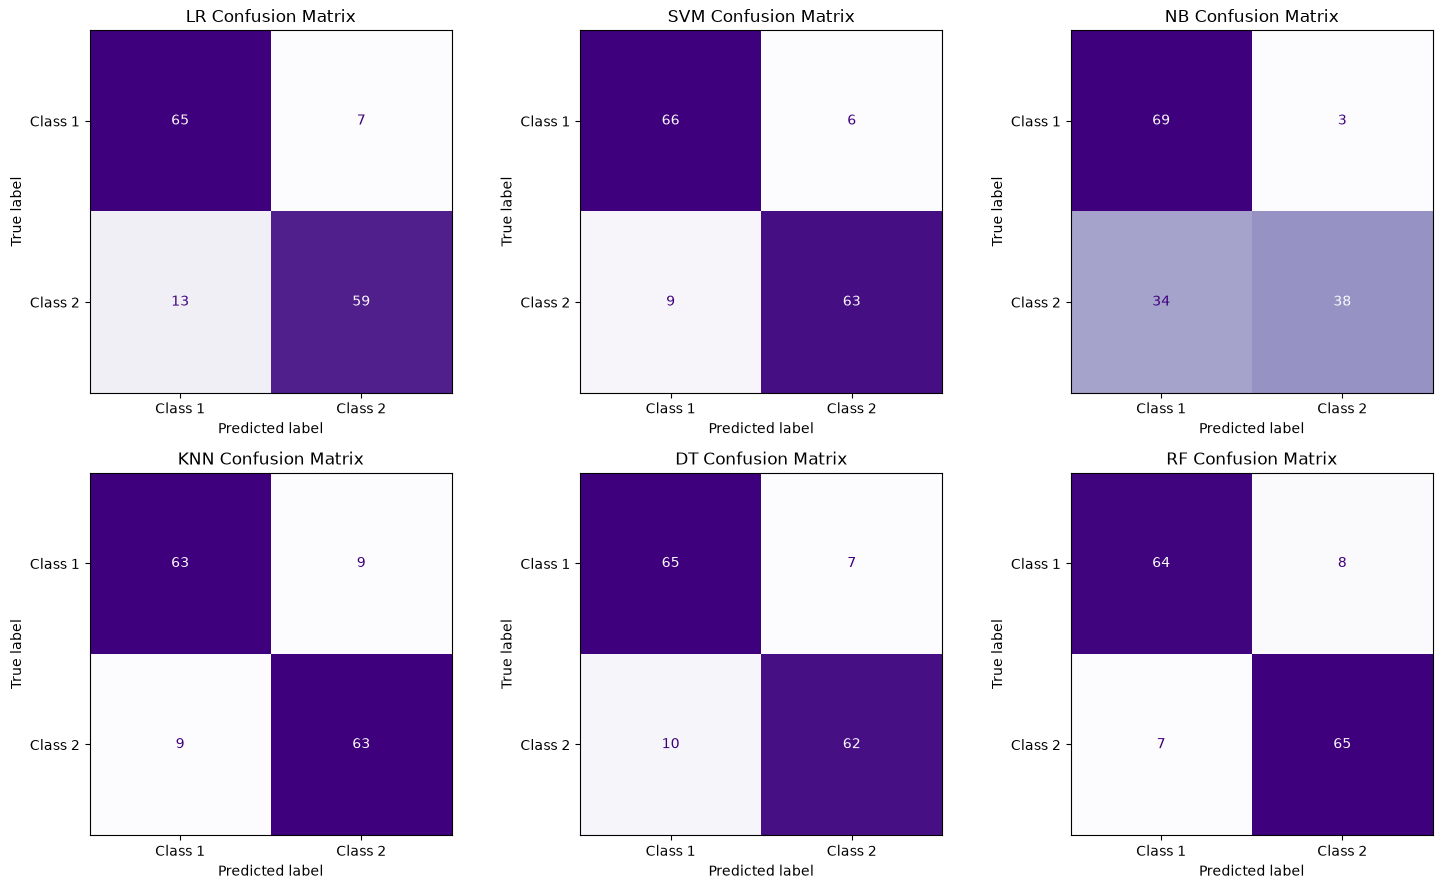

In [22]:
fig, ax = plt.subplots(2, 3, figsize=(15,9))
i = 0
for name in predictions:
    cm = confusion_matrix(y_test, predictions[name])
    disp = ConfusionMatrixDisplay(cm, display_labels=["Class 1", "Class 2"])
    disp.plot(ax=ax[i//3][i%3], cmap="Purples", colorbar=False)  
    ax[i//3][i%3].set_title(f"{name} Confusion Matrix")
    i = i + 1
plt.tight_layout()
plt.show()

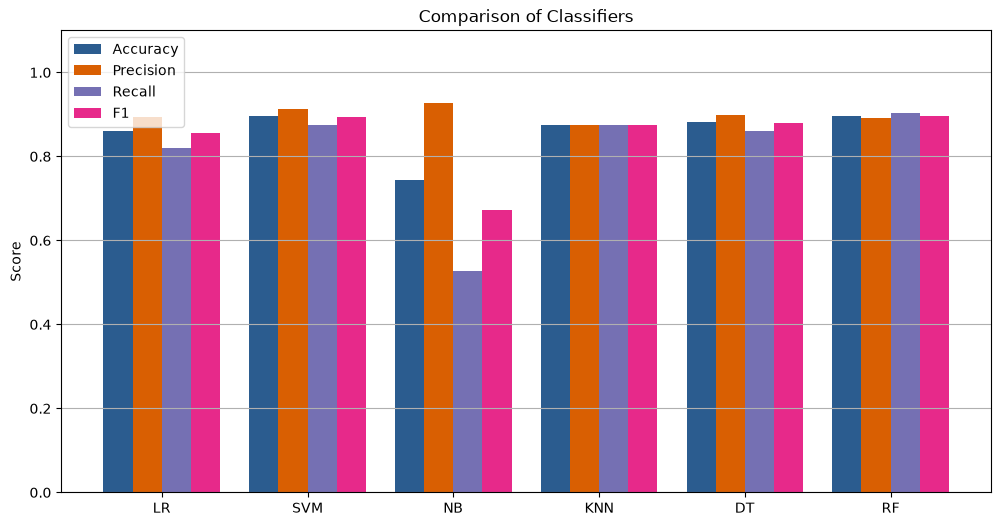

In [23]:
x = np.arange(len(res))
w = 0.2
plt.figure(figsize=(12,6))
plt.bar(x - 1.5*w, res["Accuracy"], w, label="Accuracy", color="#2b5c8f")   
plt.bar(x - 0.5*w, res["Precision"], w, label="Precision", color="#d95f02") 
plt.bar(x + 0.5*w, res["Recall"], w, label="Recall", color="#7570b3")       
plt.bar(x + 1.5*w, res["F1"], w, label="F1", color="#e7298a")             
plt.xticks(x, res["Model"])
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.title("Comparison of Classifiers")
plt.legend()
plt.grid(axis="y")
plt.show()